# Handling the imbalance on logistic regression

force the model to pay attention to classes 1 and 2, with three techniques, and measure what it changes. All resampling is applied to the **training set only**, after the split: the test set keeps its real, imbalanced distribution.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.linear_model import LogisticRegression
from src.config import SEED
from src.data import load_splits
from src.metrics import evaluate

sns.set_theme(style='whitegrid')

data, y_train, y_test = load_splits()

## The techniques

- **Class weights** (`class_weight='balanced'`): the data stays as is, but an error on a rare class costs more in the loss. Weight of class c = n / (5 × n_c).
- **Random undersampling**: randomly drop rows of the large classes until all classes have the size of the smallest one.
- **SMOTE** (k = 5): create synthetic rows of the rare classes by interpolating between a row and one of its 5 nearest neighbours, until all classes have the size of the largest one.
- **None**: the baseline of the previous notebook.

In [2]:
n = len(y_train)
weights = n / (5 * y_train.value_counts().sort_index())
weights.round(3)

Performance_Score
1    31.935
2     3.212
3     0.643
4     0.645
5     0.645
Name: count, dtype: float64

In [3]:
X = data['no_salary']['X_train_s']
for name, sampler in {'undersampling': RandomUnderSampler(random_state=SEED), 'SMOTE': SMOTE(k_neighbors=5, random_state=SEED)}.items():
    _, y_res = sampler.fit_resample(X, y_train)
    print(name, y_res.value_counts().sort_index().tolist())

/Volumes/Mathura SSD/Projets/Employee-Performance-Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
/Volumes/Mathura SSD/Projets/Employee-Performance-Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(
/Volumes/Mathura SSD/Projets/Employee-Performance-Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(


undersampling [322, 322, 322, 322, 322]
SMOTE [15999, 15999, 15999, 15999, 15999]


## Training and evaluation

Four variants on both feature sets. The test set is untouched.

In [4]:
def make(method):
    if method == 'class_weight':
        return None, LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED)
    sampler = {'none': None,
               'undersampling': RandomUnderSampler(random_state=SEED),
               'SMOTE': SMOTE(k_neighbors=5, random_state=SEED)}[method]
    return sampler, LogisticRegression(max_iter=1000, random_state=SEED)

methods = ['none', 'class_weight', 'undersampling', 'SMOTE']
rows, per_class = [], {}
for fs, d in data.items():
    for method in methods:
        sampler, model = make(method)
        X_tr, y_tr = d['X_train_s'], y_train
        if sampler is not None:
            X_tr, y_tr = sampler.fit_resample(X_tr, y_tr)
        pred = model.fit(X_tr, y_tr).predict(d['X_test_s'])
        summary, table = evaluate(y_test, pred)
        per_class[(fs, method)] = table
        rows.append({'features': fs, 'method': method, **summary,
                     'recall_1': table.loc[1, 'recall'], 'recall_2': table.loc[2, 'recall'],
                     'precision_1': table.loc[1, 'precision'], 'precision_2': table.loc[2, 'precision'],
                     'predicted_1': int((pred == 1).sum()), 'predicted_2': int((pred == 2).sum())})

results = pd.DataFrame(rows).set_index(['features', 'method'])
results.round(3)

/Volumes/Mathura SSD/Projets/Employee-Performance-Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:484: FutureWarning: `BaseEstimator._check_n_features` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_n_features` instead.
  warnings.warn(
/Volumes/Mathura SSD/Projets/Employee-Performance-Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:493: FutureWarning: `BaseEstimator._check_feature_names` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation._check_feature_names` instead.
  warnings.warn(
/Volumes/Mathura SSD/Projets/Employee-Performance-Prediction/.venv/lib/python3.9/site-packages/sklearn/base.py:474: FutureWarning: `BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.
  warnings.warn(
/Volumes/Mathura SSD/Projets/Employee-Performance-Predicti

accuracy  macro_f1  recall_1  recall_2  precision_1  \
features  method                                                               
salary    none              0.378     0.215     0.000     0.000        0.000   
          class_weight      0.261     0.190     0.475     0.155        0.013   
          undersampling     0.269     0.205     0.475     0.189        0.016   
          SMOTE             0.260     0.190     0.512     0.160        0.014   
no_salary none              0.314     0.195     0.000     0.000        0.000   
          class_weight      0.161     0.146     0.462     0.116        0.007   
          undersampling     0.205     0.168     0.212     0.169        0.007   
          SMOTE             0.158     0.147     0.438     0.166        0.007   

                         precision_2  predicted_1  predicted_2  
features  method                                                
salary    none                 0.000            0            0  
          class_weight         0.075         2865         1660  
          undersampling        0.082         2389         1847  
          SMOTE                0.079         2872         1630  
no_salary none                 0.000            0            0  
          class_weight         0.051         4954         1830  
          undersampling        0.058         2582         2340  
          SMOTE                0.060         4868         2203

## Recall per class

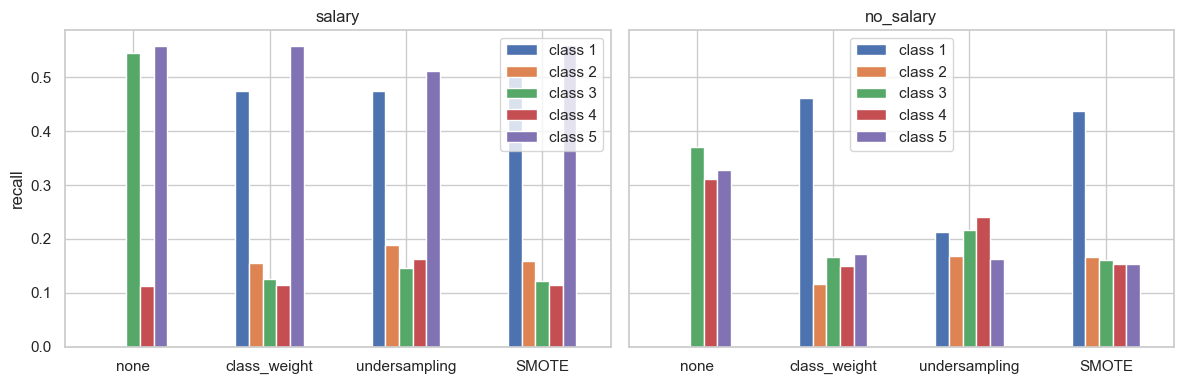

In [5]:
recall = pd.DataFrame({k: v['recall'] for k, v in per_class.items()}).T
recall.columns = [f'class {c}' for c in recall.columns]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, fs in zip(axes, data):
    recall.loc[fs].plot.bar(ax=ax, rot=0)
    ax.set_title(fs)
    ax.set_xlabel('')
axes[0].set_ylabel('recall')
plt.tight_layout()
plt.show()

## Why macro F1 does not follow the recall of class 1

Predicting class 1 more often finds more of the 80 true rows (recall goes up), but most of the predictions are wrong (precision stays tiny), so the F1 of the class stays low.

In [6]:
results[['recall_1', 'precision_1', 'predicted_1']].round(3).assign(true_class_1=int((y_test == 1).sum()))

recall_1  precision_1  predicted_1  true_class_1
features  method                                                         
salary    none              0.000        0.000            0            80
          class_weight      0.475        0.013         2865            80
          undersampling     0.475        0.016         2389            80
          SMOTE             0.512        0.014         2872            80
no_salary none              0.000        0.000            0            80
          class_weight      0.462        0.007         4954            80
          undersampling     0.212        0.007         2582            80
          SMOTE             0.438        0.007         4868            80